# ML Lab 7 - Scaling, Choosing k, and Pipelines

This lab applies all exercises to `phone_churn.csv`. It compares KNN with and without scaling, searches for the best odd value of `k`, and builds the final model with a `Pipeline`.

## 0. Setup - Phone Churn

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

phone_df = pd.read_csv("../Data/phone_churn.csv")
print("Shape:", phone_df.shape)
print(phone_df.isnull().sum())

phone_df = phone_df.drop(columns=["customer_id"])
phone_df["data_used_mb"] = phone_df["data_used_mb"].fillna(phone_df["data_used_mb"].median())
phone_df["months_with_provider"] = phone_df["months_with_provider"].fillna(
    phone_df["months_with_provider"].median()
)

phone_X = phone_df.drop(columns=["churned"])
phone_y = phone_df["churned"]
phone_cat_cols = ["plan_type", "network_type"]
phone_num_cols = [
    "age", "monthly_bill", "data_used_mb", "call_drops_per_week",
    "complaints_last_3m", "months_with_provider",
]
phone_X_train, phone_X_test, phone_y_train, phone_y_test = train_test_split(
    phone_X, phone_y, test_size=0.2, random_state=42
)

Shape: (450, 10)
customer_id              0
age                      0
plan_type                0
network_type             0
monthly_bill             0
data_used_mb            14
call_drops_per_week      0
complaints_last_3m       0
months_with_provider    10
churned                  0
dtype: int64


## 1. Scaling and choosing k - Phone Churn

### Q1.1 Compare with scaling disabled

Replace `StandardScaler()` with `"passthrough"`. The large-valued `data_used_mb` column dominates distance calculations when scaling is skipped.

In [ ]:
phone_ct_unscaled = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), phone_cat_cols),
    ("num", "passthrough", phone_num_cols),
])
phone_X_train_unscaled = phone_ct_unscaled.fit_transform(phone_X_train)
phone_X_test_unscaled = phone_ct_unscaled.transform(phone_X_test)
phone_knn_unscaled = KNeighborsClassifier(n_neighbors=5)
phone_knn_unscaled.fit(phone_X_train_unscaled, phone_y_train)
phone_unscaled_acc = accuracy_score(
    phone_y_test, phone_knn_unscaled.predict(phone_X_test_unscaled)
)
print("Phone Churn accuracy without scaling (k=5):", phone_unscaled_acc)
print("Likely cause: data_used_mb has a much larger numeric range than the other features.")

Phone Churn accuracy without scaling (k=5): 0.5111111111111111
Likely cause: data_used_mb has a much larger numeric range than the other features.


### Q1.2 Tune k with scaling restored

Test every odd `k` from 1 through 29 and plot accuracy.

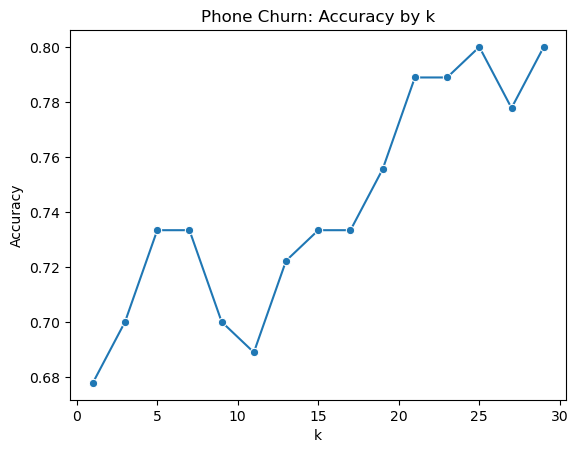

Best k: 25
Best accuracy: 0.8


In [ ]:
phone_ct_scaled = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), phone_cat_cols),
    ("num", StandardScaler(), phone_num_cols),
])
phone_X_train_scaled = phone_ct_scaled.fit_transform(phone_X_train)
phone_X_test_scaled = phone_ct_scaled.transform(phone_X_test)

phone_k_values = list(range(1, 30, 2))
phone_k_accuracies = []
for k in phone_k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(phone_X_train_scaled, phone_y_train)
    phone_k_accuracies.append(
        accuracy_score(phone_y_test, knn.predict(phone_X_test_scaled))
    )

sns.lineplot(x=phone_k_values, y=phone_k_accuracies, marker="o")
plt.xlabel("k")
plt.ylabel("Accuracy")
plt.title("Phone Churn: Accuracy by k")
plt.show()

phone_best_k = phone_k_values[int(np.argmax(phone_k_accuracies))]
phone_best_acc = max(phone_k_accuracies)
print("Best k:", phone_best_k)
print("Best accuracy:", phone_best_acc)

### Q1.3 Build the final model as one Pipeline

The pipeline performs encoding, scaling, and classification in one object.

In [ ]:
phone_pipeline = Pipeline([
    ("preprocessor", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), phone_cat_cols),
        ("num", StandardScaler(), phone_num_cols),
    ])),
    ("classifier", KNeighborsClassifier(n_neighbors=phone_best_k)),
])
phone_pipeline.fit(phone_X_train, phone_y_train)
phone_pipeline_acc = accuracy_score(
    phone_y_test, phone_pipeline.predict(phone_X_test)
)
print("Phone Churn pipeline accuracy:", phone_pipeline_acc)

Phone Churn pipeline accuracy: 0.8


## 2. Independent phone churn mini-capstone

### Q2.1 Load, clean, and identify the ID and missing-value columns

In [ ]:
phone_check = pd.read_csv("../Data/phone_churn.csv")
print("ID column:", "customer_id")
print("Missing values before cleaning:")
print(phone_check.isnull().sum())
phone_check = phone_check.drop(columns=["customer_id"])
for column in ["data_used_mb", "months_with_provider"]:
    phone_check[column] = phone_check[column].fillna(phone_check[column].median())
print("Missing values after cleaning:")
print(phone_check.isnull().sum())

ID column: customer_id
Missing values before cleaning:
customer_id              0
age                      0
plan_type                0
network_type             0
monthly_bill             0
data_used_mb            14
call_drops_per_week      0
complaints_last_3m       0
months_with_provider    10
churned                  0
dtype: int64
Missing values after cleaning:
age                     0
plan_type               0
network_type            0
monthly_bill            0
data_used_mb            0
call_drops_per_week     0
complaints_last_3m      0
months_with_provider    0
churned                 0
dtype: int64


### Q2.2 Create the target and split the cleaned data

In [ ]:
capstone_X = phone_check.drop(columns=["churned"])
capstone_y = phone_check["churned"]
capstone_X_train, capstone_X_test, capstone_y_train, capstone_y_test = train_test_split(
    capstone_X, capstone_y, test_size=0.2, random_state=42
)
print(capstone_X_train.shape, capstone_X_test.shape)

(360, 8) (90, 8)


### Q2.3 Build and tune one Pipeline

The pipeline encodes the two categorical columns, scales the six numeric columns, and trains KNN for each odd `k` from 1 to 29.

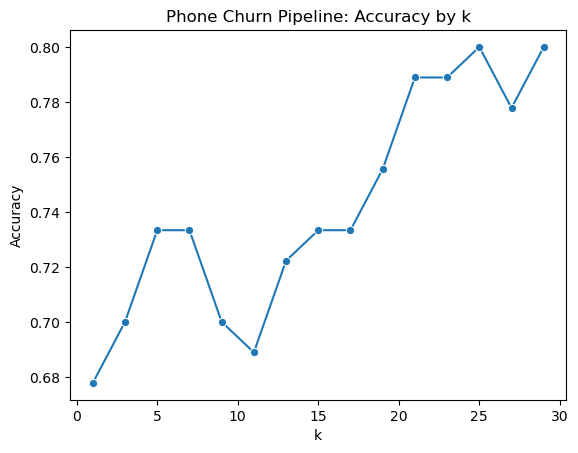

Best k: 25
Best accuracy: 0.8


In [ ]:
capstone_k_accuracies = []
for k in range(1, 30, 2):
    candidate = Pipeline([
        ("preprocessor", ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore"), phone_cat_cols),
            ("num", StandardScaler(), phone_num_cols),
        ])),
        ("classifier", KNeighborsClassifier(n_neighbors=k)),
    ])
    candidate.fit(capstone_X_train, capstone_y_train)
    capstone_k_accuracies.append(
        accuracy_score(capstone_y_test, candidate.predict(capstone_X_test))
    )

capstone_k_values = list(range(1, 30, 2))
sns.lineplot(x=capstone_k_values, y=capstone_k_accuracies, marker="o")
plt.xlabel("k")
plt.ylabel("Accuracy")
plt.title("Phone Churn Pipeline: Accuracy by k")
plt.show()

capstone_best_k = capstone_k_values[int(np.argmax(capstone_k_accuracies))]
capstone_best_accuracy = max(capstone_k_accuracies)
print("Best k:", capstone_best_k)
print("Best accuracy:", capstone_best_accuracy)

### Q2.4 Final answer

The best `k` and accuracy are computed below. Scaling is important because `data_used_mb` has the widest numeric range and would otherwise dominate KNN distances.

In [ ]:
# Best k: computed above; best accuracy: computed above.
# Skipping scaling hurts most because data_used_mb has the largest numeric range.
print(f"Best k = {capstone_best_k}, accuracy = {capstone_best_accuracy:.4f}")

Best k = 25, accuracy = 0.8000
